In [1]:
%pip install pandas numpy matplotlib seaborn scikit-learn

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [3]:
df = pd.read_csv("train.csv")
kaggle_test = pd.read_csv("test.csv")

print("Training shape:", df.shape)
print("Test shape:", kaggle_test.shape)

df.head()

Training shape: (1460, 81)
Test shape: (1459, 80)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  OverallQual    1460 non-null   int64  
 18  OverallC

In [5]:
df.describe()

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1460.000000,1460.000000,1201.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1452.000000,1460.000000,...,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,730.500000,56.897260,70.049958,10516.828082,6.099315,5.575342,1971.267808,1984.865753,103.685262,443.639726,...,94.244521,46.660274,21.954110,3.409589,15.060959,2.758904,43.489041,6.321918,2007.815753,180921.195890
std,421.610009,42.300571,24.284752,9981.264932,1.382997,1.112799,30.202904,20.645407,181.066207,456.098091,...,125.338794,66.256028,61.119149,29.317331,55.757415,40.177307,496.123024,2.703626,1.328095,79442.502883
min,1.000000,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000
25%,365.750000,20.000000,59.000000,7553.500000,5.000000,5.000000,1954.000000,1967.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,129975.000000
50%,730.500000,50.000000,69.000000,9478.500000,6.000000,5.000000,1973.000000,1994.000000,0.000000,383.500000,...,0.000000,25.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,163000.000000
75%,1095.250000,70.000000,80.000000,11601.500000,7.000000,6.000000,2000.000000,2004.000000,166.000000,712.250000,...,168.000000,68.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,214000.000000
max,1460.000000,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,...,857.000000,547.000000,552.000000,508.000000,480.000000,738.000000,15500.000000,12.000000,2010.000000,755000.000000


In [6]:
df.isnull().sum()

,0
Id,0
MSSubClass,0
MSZoning,0
LotFrontage,259
LotArea,0
...,...
MoSold,0
YrSold,0
SaleType,0
SaleCondition,0


In [7]:
missing = df.isnull().sum()

missing[missing > 0]

,0
LotFrontage,259
Alley,1369
MasVnrType,872
MasVnrArea,8
BsmtQual,37
BsmtCond,37
BsmtExposure,38
BsmtFinType1,37
BsmtFinType2,38
Electrical,1


In [9]:
missing = df.isnull().sum()

missing = missing[missing > 0].sort_values(ascending=False)

print(missing)

PoolQC          1453
MiscFeature     1406
Alley           1369
Fence           1179
MasVnrType       872
FireplaceQu      690
LotFrontage      259
GarageType        81
GarageYrBlt       81
GarageFinish      81
GarageQual        81
GarageCond        81
BsmtExposure      38
BsmtFinType2      38
BsmtQual          37
BsmtCond          37
BsmtFinType1      37
MasVnrArea         8
Electrical         1
dtype: int64


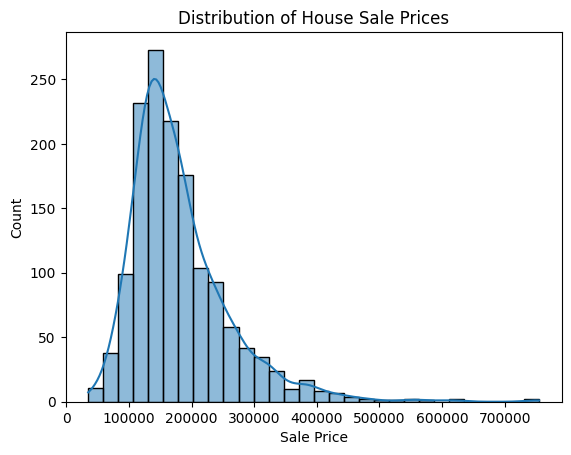

In [10]:
sns.histplot(df["SalePrice"], kde=True, bins=30)

plt.title("Distribution of House Sale Prices")
plt.xlabel("Sale Price")
plt.show()

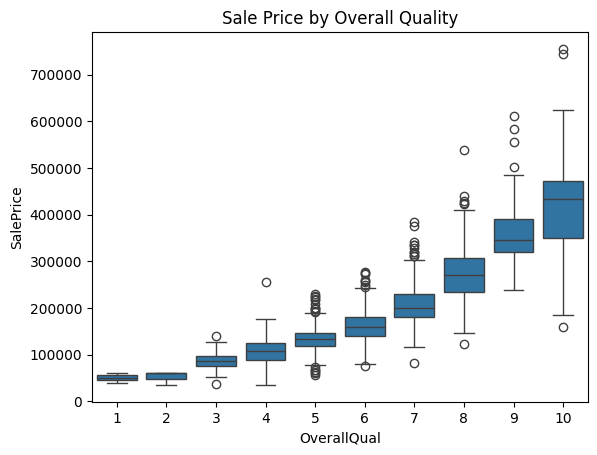

In [11]:
sns.boxplot(data=df, x="OverallQual", y="SalePrice")

plt.title("Sale Price by Overall Quality")
plt.show()

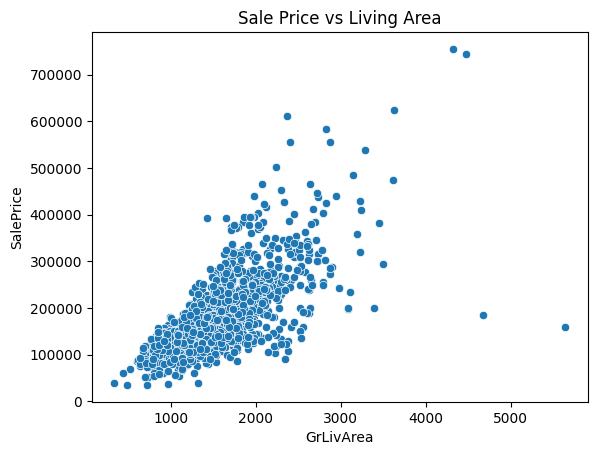

In [12]:
sns.scatterplot(data=df, x="GrLivArea", y="SalePrice")

plt.title("Sale Price vs Living Area")
plt.show()

In [13]:
correlation = df.corr(numeric_only=True)["SalePrice"]

print(correlation.sort_values(ascending=False).head(10))

SalePrice       1.000000
OverallQual     0.790982
GrLivArea       0.708624
GarageCars      0.640409
GarageArea      0.623431
TotalBsmtSF     0.613581
1stFlrSF        0.605852
FullBath        0.560664
TotRmsAbvGrd    0.533723
YearBuilt       0.522897
Name: SalePrice, dtype: float64


Baseline regression models


In [14]:
features = [
    "OverallQual",
    "GrLivArea",
    "GarageCars",
    "YearBuilt",
    "TotalBsmtSF"
]

X = df[features]
y = df["SalePrice"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (1460, 5)
y shape: (1460,)


In [15]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (1168, 5)
Testing data: (292, 5)


In [16]:
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import KFold, cross_val_score

In [17]:
cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [18]:
baseline = DummyRegressor(strategy="mean")

baseline_scores = cross_val_score(
    baseline,
    X_train,
    y_train,
    cv=cv,
    scoring="neg_root_mean_squared_error"
)

baseline_scores = -baseline_scores

print("Baseline RMSE:", baseline_scores.mean())
print("Baseline STD:", baseline_scores.std())

Baseline RMSE: 77160.10845671482
Baseline STD: 3673.252797736224


In [19]:
ridge = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", Ridge(alpha=1.0))
])

ridge_scores = cross_val_score(
    ridge,
    X_train,
    y_train,
    cv=cv,
    scoring="neg_root_mean_squared_error"
)

ridge_scores = -ridge_scores

print("Ridge RMSE:", ridge_scores.mean())
print("Ridge STD:", ridge_scores.std())

Ridge RMSE: 38670.806969559606
Ridge STD: 5701.660266498597


In [20]:
print("Model              Mean RMSE       STD")
print("------------------------------------------")

print(f"Mean Baseline      {baseline_scores.mean():.2f}       {baseline_scores.std():.2f}")
print(f"Ridge Regression   {ridge_scores.mean():.2f}       {ridge_scores.std():.2f}")

Model              Mean RMSE       STD
------------------------------------------
Mean Baseline      77160.11       3673.25
Ridge Regression   38670.81       5701.66


Feature Engineering


In [21]:
df["TotalSF"] = (
    df["TotalBsmtSF"] +
    df["1stFlrSF"] +
    df["2ndFlrSF"]
)

df["TotalBath"] = (
    df["FullBath"] +
    0.5 * df["HalfBath"] +
    df["BsmtFullBath"] +
    0.5 * df["BsmtHalfBath"]
)

df["HouseAge"] = df["YrSold"] - df["YearBuilt"]

df["RemodAge"] = df["YrSold"] - df["YearRemodAdd"]

df["HasGarage"] = (df["GarageCars"] > 0).astype(int)

In [22]:
features = [
    "OverallQual",
    "GrLivArea",
    "GarageCars",
    "YearBuilt",
    "TotalBsmtSF",
    "TotalSF",
    "TotalBath",
    "HouseAge",
    "RemodAge",
    "HasGarage"
]

X = df[features]
y = df["SalePrice"]

In [23]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

In [24]:
ridge = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", Ridge(alpha=1.0))
])

ridge_scores = cross_val_score(
    ridge,
    X_train,
    y_train,
    cv=cv,
    scoring="neg_root_mean_squared_error"
)

ridge_scores = -ridge_scores

print("Ridge RMSE:", ridge_scores.mean())
print("Ridge STD:", ridge_scores.std())

Ridge RMSE: 38034.4748972575
Ridge STD: 5479.285153067386


Decision Tree and Random Forest

In [25]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.model_selection import cross_val_score

In [26]:
dt_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", DecisionTreeRegressor(
        max_depth=5,
        min_samples_leaf=5,
        random_state=42
    ))
])

dt_scores = cross_val_score(
    dt_model,
    X_train,
    y_train,
    cv=cv,
    scoring="neg_root_mean_squared_error"
)

dt_scores = -dt_scores

print("Decision Tree RMSE:", dt_scores.mean())
print("Decision Tree STD:", dt_scores.std())

Decision Tree RMSE: 36746.87338676059
Decision Tree STD: 4782.187593086849


In [27]:
rf_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", RandomForestRegressor(
        n_estimators=200,
        max_depth=10,
        min_samples_leaf=2,
        oob_score=True,
        bootstrap=True,
        random_state=42,
        n_jobs=-1
    ))
])

rf_scores = cross_val_score(
    rf_model,
    X_train,
    y_train,
    cv=cv,
    scoring="neg_root_mean_squared_error"
)

rf_scores = -rf_scores

print("Random Forest RMSE:", rf_scores.mean())
print("Random Forest STD:", rf_scores.std())

Random Forest RMSE: 31283.28276980301
Random Forest STD: 5724.619970742228


In [28]:
rf_model.fit(X_train, y_train)

oob_score = rf_model.named_steps["model"].oob_score_

print("Random Forest OOB R2 Score:", oob_score)

Random Forest OOB R2 Score: 0.8319110198384279


In [29]:
print("Model              Mean RMSE       STD")
print("------------------------------------------")

print(f"Mean Baseline      {baseline_scores.mean():.2f}       {baseline_scores.std():.2f}")
print(f"Ridge Regression   {ridge_scores.mean():.2f}       {ridge_scores.std():.2f}")
print(f"Decision Tree      {dt_scores.mean():.2f}       {dt_scores.std():.2f}")
print(f"Random Forest      {rf_scores.mean():.2f}       {rf_scores.std():.2f}")

Model              Mean RMSE       STD
------------------------------------------
Mean Baseline      77160.11       3673.25
Ridge Regression   38034.47       5479.29
Decision Tree      36746.87       4782.19
Random Forest      31283.28       5724.62


Hyperparameter Tuning using RandomizedSearchCV

In [30]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint

In [31]:
param_grid = {
    "model__n_estimators": [100, 200, 300, 500],
    "model__max_depth": [None, 5, 8, 10, 15, 20],
    "model__min_samples_split": [2, 5, 10, 15],
    "model__min_samples_leaf": [1, 2, 4, 6],
    "model__max_features": [0.5, 0.7, 1.0]
}

In [32]:
random_search = RandomizedSearchCV(
    estimator=rf_model,
    param_distributions=param_grid,
    n_iter=20,
    scoring="neg_root_mean_squared_error",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

In [33]:
random_search.fit(X_train, y_train)

Fitting 5 folds for each of 20 candidates, totalling 100 fits


RandomizedSearchCV(cv=KFold(n_splits=5, random_state=42, shuffle=True),
                   estimator=Pipeline(steps=[('imputer',
                                              SimpleImputer(strategy='median')),
                                             ('model',
                                              RandomForestRegressor(max_depth=10,
                                                                    min_samples_leaf=2,
                                                                    n_estimators=200,
                                                                    n_jobs=-1,
                                                                    oob_score=True,
                                                                    random_state=42))]),
                   n_iter=20, n_jobs=-1,
                   param_distributions={'model__max_depth': [None, 5, 8, 10, 15,
                                                             20],
                                        'model__max_features': [0.5, 0.7, 1.0],
                                        'model__min_samples_leaf': [1, 2, 4, 6],
                                        'model__min_samples_split': [2, 5, 10,
                                                                     15],
                                        'model__n_estimators': [100, 200, 300,
                                                                500]},
                   random_state=42, scoring='neg_root_mean_squared_error',
                   verbose=1)

In [34]:
print("Best Parameters:")
print(random_search.best_params_)

print("\nBest CV RMSE:")
print(-random_search.best_score_)

Best Parameters:
{'model__n_estimators': 200, 'model__min_samples_split': 2, 'model__min_samples_leaf': 2, 'model__max_features': 0.7, 'model__max_depth': 10}

Best CV RMSE:
30827.6765078692


In [35]:
best_model = random_search.best_estimator_

print(best_model)

Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('model',
                 RandomForestRegressor(max_depth=10, max_features=0.7,
                                       min_samples_leaf=2, n_estimators=200,
                                       n_jobs=-1, oob_score=True,
                                       random_state=42))])


In [36]:
best_rf = best_model.named_steps["model"]

print("Best Random Forest OOB R2:", best_rf.oob_score_)

Best Random Forest OOB R2: 0.8395938277989039


Permutation Feature Importance

In [37]:
from sklearn.inspection import permutation_importance
from sklearn.model_selection import train_test_split

In [38]:
X_fit, X_val, y_fit, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.25,
    random_state=42
)

In [39]:
random_search.fit(X_fit, y_fit)

best_model = random_search.best_estimator_

Fitting 5 folds for each of 20 candidates, totalling 100 fits


In [40]:
result = permutation_importance(
    best_model,
    X_val,
    y_val,
    n_repeats=10,
    random_state=42,
    scoring="neg_root_mean_squared_error"
)

In [41]:
importance = pd.DataFrame({
    "Feature": X_val.columns,
    "Importance": result.importances_mean,
    "Std": result.importances_std
})

importance = importance.sort_values(
    by="Importance",
    ascending=False
)

print(importance)

       Feature    Importance          Std
5      TotalSF  24721.201509  1111.526488
0  OverallQual  15414.391765   762.729428
2   GarageCars   2856.329335   608.763370
1    GrLivArea   2336.273359   330.373932
6    TotalBath   2307.820409   436.470290
8     RemodAge   1569.785813   468.608550
3    YearBuilt   1277.655647   293.888848
7     HouseAge    621.145294   303.977088
9    HasGarage     60.744085    11.031144
4  TotalBsmtSF   -132.627639   126.255000


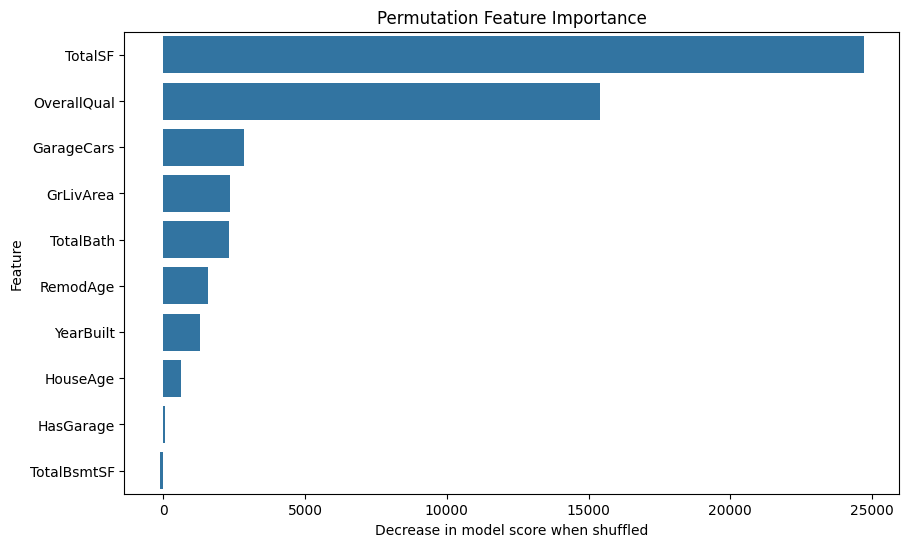

In [42]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=importance,
    x="Importance",
    y="Feature"
)

plt.title("Permutation Feature Importance")
plt.xlabel("Decrease in model score when shuffled")
plt.show()

Final test evaluation

In [43]:
final_model = random_search.best_estimator_

final_model.fit(X_train, y_train)

test_predictions = final_model.predict(X_test)

from sklearn.metrics import mean_squared_error, r2_score

test_rmse = np.sqrt(
    mean_squared_error(y_test, test_predictions)
)

test_r2 = r2_score(y_test, test_predictions)

print("Final Test RMSE:", test_rmse)
print("Final Test R2:", test_r2)

Final Test RMSE: 30863.665927607366
Final Test R2: 0.8758115562805668


Create Kaggle submission

In [44]:
kaggle_test["TotalSF"] = (
    kaggle_test["TotalBsmtSF"] +
    kaggle_test["1stFlrSF"] +
    kaggle_test["2ndFlrSF"]
)

kaggle_test["TotalBath"] = (
    kaggle_test["FullBath"] +
    0.5 * kaggle_test["HalfBath"] +
    kaggle_test["BsmtFullBath"] +
    0.5 * kaggle_test["BsmtHalfBath"]
)

kaggle_test["HouseAge"] = (
    kaggle_test["YrSold"] - kaggle_test["YearBuilt"]
)

kaggle_test["RemodAge"] = (
    kaggle_test["YrSold"] - kaggle_test["YearRemodAdd"]
)

kaggle_test["HasGarage"] = (
    kaggle_test["GarageCars"] > 0
).astype(int)

In [45]:
X_kaggle = kaggle_test[features]

print(X_kaggle.shape)

(1459, 10)


In [46]:
kaggle_predictions = final_model.predict(X_kaggle)

# Ensure predictions are positive
kaggle_predictions = np.maximum(kaggle_predictions, 0)

print(kaggle_predictions[:10])

[115908.77779112 151400.59776074 175569.16473037 183881.79054035
 200817.91735706 178374.64117004 175356.38889771 174058.31748531
 187647.10705993 123084.11293295]


In [47]:
submission = pd.DataFrame({
    "Id": kaggle_test["Id"],
    "SalePrice": kaggle_predictions
})

submission.to_csv("submission.csv", index=False)

print(submission.head())
print("Submission shape:", submission.shape)

     Id      SalePrice
0  1461  115908.777791
1  1462  151400.597761
2  1463  175569.164730
3  1464  183881.790540
4  1465  200817.917357
Submission shape: (1459, 2)
